In [1]:
import os

model_path = r"D:\basic python\Facemask\mask_detector.h5"

print(os.path.exists(model_path))

True


In [2]:
import os

folder_path = r"D:\basic python\Facemask"

if os.path.exists(folder_path):
    print(os.listdir(folder_path))
else:
    print("Folder not found!")
    

['.gitignore', '.ipynb_checkpoints', 'CODE_OF_CONDUCT.md', 'dataset', 'detect_mask_image.py', 'detect_mask_video.py', 'Facemask', 'face_detector', 'LICENSE', 'mask_detector.h5', 'plot.png', 'README.md', 'Readme_images', 'requirements.txt', 'search.py', 'train_mask_detector.py', 'Untitled1.ipynb']


In [3]:
import os

model_path = r"D:\basic python\Facemask\mask_detector.model"

print(os.path.exists(model_path))

False


In [4]:
import tensorflow as tf

model_path = r"D:\basic python\Facemask\mask_detector.h5"

maskNet = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Mask detector loaded successfully!")

Mask detector loaded successfully!


In [5]:

%pip install opencv-python


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV installed successfully!")

OpenCV version: 5.0.0
OpenCV installed successfully!


In [7]:

import cv2

print("Version:", getattr(cv2, "__version__", "Unknown"))
print("Location:", getattr(cv2, "__file__", "Unknown"))
print("DNN module:", cv2.dnn)
print("Available Caffe functions:",
      [x for x in dir(cv2.dnn) if "Caffe" in x or "Net" in x])


Version: 5.0.0
Location: C:\Users\Gayathri R\AppData\Roaming\Python\Python314\site-packages\cv2\__init__.py
DNN module: <module 'cv2.dnn' (namespace) from ['C:\\Users\\Gayathri R\\AppData\\Roaming\\Python\\Python314\\site-packages\\cv2\\dnn']>
Available Caffe functions: ['Net', 'Net_readFromModelOptimizer', 'readNet', 'readNetFromModelOptimizer', 'readNetFromONNX', 'readNetFromTFLite', 'readNetFromTensorflow']


In [9]:
import cv2

print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("OpenCV file:", getattr(cv2, "__file__", "Unknown"))
print("DNN module file:", getattr(cv2.dnn, "__file__", "Unknown"))
print("Has readNet:", hasattr(cv2.dnn, "readNet"))
print("Has readNetFromCaffe:",
      hasattr(cv2.dnn, "readNetFromCaffe"))

OpenCV version: 5.0.0
OpenCV file: C:\Users\Gayathri R\AppData\Roaming\Python\Python314\site-packages\cv2\__init__.py
DNN module file: None
Has readNet: True
Has readNetFromCaffe: False


In [10]:

%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [11]:

%pip install opencv-python==4.13.0.92


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/40.2 MB ? eta -:--:--
    --------------------------------------- 0.5/40.2 MB 873.5 kB/s eta 0:00:46
    --------------------------------------- 0.8/40.2 MB 1.1 MB/s eta 0:00:36
    --------------------------------------- 0.8/40.2 MB 1.1 MB/s eta 0:00:36
   - -------------------------------------- 1.0/40.2 MB 870.8 kB/s eta 0:00:45
   - -------------------------------------- 1.3/40.2 MB 856.9 kB/s eta 0:00:46
   - -------------------------------------- 1.6/40.2 MB 926.0 kB/s eta 0:00:42
   - -------------------------------------- 1.8/40.2 MB 1.0 MB/s eta 0:00:38
   -- ------------------------------------- 2.4/40.2 MB 1.2 MB/s eta 0:00:33
   -- ------------------------------------- 2.9/40.2 MB 1.3 MB/s eta 0:00:29
   --- ----

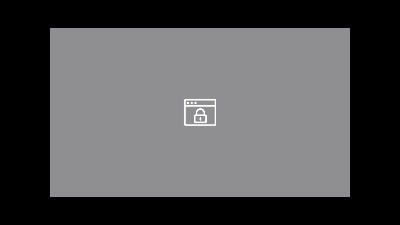

In [ ]:
# Import libraries
from pathlib import Path
import cv2
import numpy as np
import time
import tensorflow as tf
from IPython.display import display, Image, clear_output
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
# Set project paths
PROJECT_DIR = Path(r"D:\basic python\Facemask")
FACE_DIR = PROJECT_DIR / "face_detector"
PROTOTXT = FACE_DIR / "deploy.prototxt"
WEIGHTS = FACE_DIR / "res10_300x300_ssd_iter_140000.caffemodel"
MASK_MODEL = PROJECT_DIR / "mask_detector.h5"
# Check required files
for path in [PROTOTXT, WEIGHTS, MASK_MODEL]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")
# Load the face detection model
print("Loading face detector...")
faceNet = cv2.dnn.readNetFromCaffe(str(PROTOTXT), str(WEIGHTS))
# Load the trained mask classification model
print("Loading mask detection model...")
maskNet = tf.keras.models.load_model(str(MASK_MODEL), compile=False)
print("Models loaded successfully!")
# Define face detection and mask prediction
def detect_and_predict_mask(frame, faceNet, maskNet, threshold=0.5):
    h, w = frame.shape[:2]
    # Prepare image for face detection
    blob = cv2.dnn.blobFromImage(
        frame, 1.0, (300, 300), (104.0, 177.0, 123.0)
    )
    faceNet.setInput(blob)
    detections = faceNet.forward()
    faces = []
    locations = []
    # Extract detected face regions
    for i in range(detections.shape[2]):
        confidence = float(detections[0, 0, i, 2])
        if confidence < threshold:
            continue
        box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])
        startX, startY, endX, endY = box.astype(int)
        startX = max(0, startX)
        startY = max(0, startY)
        endX = min(w, endX)
        endY = min(h, endY)
        if endX <= startX or endY <= startY:
            continue
        # Prepare face image for MobileNetV2
        face = frame[startY:endY, startX:endX]
        face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
        face = cv2.resize(face, (224, 224))
        face = preprocess_input(face.astype("float32"))
        faces.append(face)
        locations.append((startX, startY, endX, endY))
    # Predict mask status
    if faces:
        batch = np.asarray(faces, dtype="float32")
        predictions = maskNet.predict(batch, verbose=0)
        predictions = np.asarray(predictions)
    else:
        predictions = np.empty((0, 2))
    return locations, predictions
# Start webcam
camera = cv2.VideoCapture(0)
if not camera.isOpened():
    camera.release()
    raise RuntimeError(
        "Webcam unavailable. Check permissions or try camera index 1."
    )
print("Webcam started. Interrupt the cell to stop.")
try:
    while True:
        # Read webcam frame
        success, frame = camera.read()
        if not success:
            print("Unable to read webcam frame.")
            break
        # Resize frame
        new_width = 400
        new_height = int(frame.shape[0] * new_width / frame.shape[1])
        frame = cv2.resize(frame, (new_width, new_height))
        # Detect faces and predict mask status
        locations, predictions = detect_and_predict_mask(
            frame, faceNet, maskNet
        )
        # Draw bounding boxes and labels
        for (box, pred) in zip(locations, predictions):
            startX, startY, endX, endY = box
            mask_score, without_mask_score = pred[:2]
            if mask_score > without_mask_score:
                label = "Mask: You are allowed"
                color = (0, 255, 0)
            else:
                label = "No Mask: You are not allowed"
                color = (0, 0, 255)
            cv2.rectangle(
                frame, (startX, startY), (endX, endY), color, 2
            )
            cv2.putText(
                frame, label, (startX, max(20, startY - 10)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 2
            )
        # Display frame inside Jupyter Notebook
        encoded_ok, encoded_frame = cv2.imencode(".jpg", frame)
        if encoded_ok:
            clear_output(wait=True)
            display(Image(data=encoded_frame.tobytes()))
        time.sleep(0.03)
except KeyboardInterrupt:
    print("Webcam stopped.")
finally:
    camera.release()
    print("Webcam resources released.")